# Noh implosion against Noh (1987)

Cold gas (rho0 = 1, |u0| = 1, p0 = 1e-6, gamma = 5/3) streams into a wall (planar) or onto the
axis (cylindrical, 2D). A shock moves out at D = (gamma - 1)/2 |u0| = 1/3; behind it the gas is at
rest with rho = rho0 ((gamma+1)/(gamma-1))^d = 4 (planar), 16 (2D) and p = 4/3, 16/3
(Noh 1987, J. Comput. Phys. 72, 78; ExactPack `noh1.py`). Ahead of the 2D shock the converging
inflow is compressed, rho = rho0 (1 + |u0| t / r).

The setups are those of `tests/test_hydro_hard_noh_planar.py` and
`tests/test_hydro_hard_noh_multid.py`: reflecting walls everywhere, the inflow brought to rest
towards the far walls by a ramp so no vacuum opens there, measured at t = 0.6 in the region
r < 0.3 that the ramp has not reached. Compared: L1 of rho, u, p (planar, leaving out the 4
wall cells with the known wall-heating dip) and L1(rho) in the quarter disc (2D), next to the
test's measured values; the planar order over 256-1024 cells per unit length.
The test also runs MC, van Leer and HLL ladders and the 3D case.

Runtime: about 20 seconds on four CPU cores (an A100 node's CPU cores via SLURM, JAX on the CPU), including JAX start-up and compilation, which dominate.

In [1]:
import os
os.environ.setdefault("JAX_PLATFORMS", "cpu")   # this notebook is sized for a CPU; unset it to use a GPU

import contextlib, io, time
from dataclasses import replace
import numpy as np
import matplotlib.pyplot as plt
from luna import Config, launch


def run(cfg, **state):
    """launch(cfg, **state), as `python main.py` runs it (state: U0= or ic=, an initial state of our own),
    with its log kept out of the notebook; (RunResult, wall s)."""
    t0 = time.time()
    with contextlib.redirect_stdout(io.StringIO()):
        res = launch(cfg, **state)
    return res, time.time() - t0


# FP64, PLM, HLLC, quiet: the settings of LUNA's accuracy tests
QUIET = dict(enable_x64=True, ORDER=1, LIMITER=0, riemann_solver="hllc", PLOT_AFTER_SIM=False,
             output_cadence=10**6, diag_interval=10**6, enable_checkpointing=False, clear_output_dir=True)
BASE = replace(Config(), **QUIET)

**A custom initial state through the run path.** LUNA's registered problems (`test_problem`) fix
their initial states. A state of our own goes to `launch(cfg, U0=U)`: `U` holds the conserved
variables on the whole grid in the run's own dimension, `(3, Nx)` in 1D (rho, rho vx, E),
`(4, Nx, Ny)` in 2D, `(5, Nx, Ny, Nz)` in 3D, energy last; a shape that does not fit the config is
refused. It takes the path `python main.py` takes (`luna/ic_generation/user_ic.py`), sharded like a
registered problem; `test_problem` then only names the run.

In [2]:
G, RHO0, U_IN, P0 = 5.0 / 3.0, 1.0, -1.0, 1e-6
T, X_MAX, SKIP = 0.6, 0.3, 4
D = (G - 1) / 2 * abs(U_IN)


def smoothstep(s):
    s = np.clip(s, 0.0, 1.0)
    return s * s * (3.0 - 2.0 * s)

## Planar

The box is [0, 2] (2N cells for N per unit length); inflow at u0 on [0, 1], ramped to rest on [1, 2].

In [3]:
L1D, A1D = 2.0, 1.0
RHO_S, P_S = RHO0 * (G + 1) / (G - 1), (G - 1) / 2 * RHO0 * (G + 1) / (G - 1) * U_IN ** 2


def planar(n, solver="hllc"):
    """(rho, u, p) at T on the 2n cells of [0, 2]."""
    x = (np.arange(2 * n) + 0.5) / n
    u = U_IN * np.clip((L1D - x) / (L1D - A1D), 0.0, 1.0)
    U = np.zeros((3, 2 * n))                      # rho, rho u, E
    U[0], U[1], U[2] = RHO0, RHO0 * u, P0 / (G - 1) + 0.5 * RHO0 * u * u
    cfg = replace(BASE, test_problem="Noh-Planar", SPATIAL_DIMENSION=1, Nx=2 * n,
                  Lx=L1D, BOUNDARY=2, gamma=G, t_end=T, riemann_solver=solver,
                  write_snapshots=False, output_dir="snapshots/nb05/run")
    res, wall = run(cfg, U0=U)
    V = np.asarray(res.extra["U"], np.float64)
    rho, u = V[0], V[1] / V[0]
    return (rho, u, (G - 1) * (V[2] - 0.5 * rho * u * u)), wall


def planar_exact(n, t=T):
    """Exact cell averages on the cells of [0, X_MAX]."""
    edges = np.arange(int(round(X_MAX * n)) + 1) / n
    f = np.clip((D * t - edges[:-1]) * n, 0.0, 1.0)          # shocked fraction of each cell
    return f * RHO_S + (1 - f) * RHO0, (1 - f) * U_IN, f * P_S + (1 - f) * P0


# measured by the test (CPU, FP64): HLLC-minmod N=256: 0.00372 0.00173 0.00151, 512: 0.00163 ..,
# 1024: 0.000725 ..; HLL-minmod N=256: 0.00524 0.00176 0.00184
ns, errs, prof = (256, 512, 1024), {}, {}
for solver, nlist in (("hllc", ns), ("hll", (256,))):
    for n in nlist:
        num, wall = planar(n, solver)
        ex = planar_exact(n)
        m = len(ex[0])
        errs[solver, n] = [float(np.abs(a[SKIP:m] - b[SKIP:]).sum()) / n for a, b in zip(num, ex)]
        prof[solver, n] = num[0]
        print(f"{solver:4s} N={n:5d}: L1 rho, u, p = " + ", ".join(f"{v:.3e}" for v in errs[solver, n])
              + f"   ({wall:.1f} s)")
order = -np.polyfit(np.log(ns), np.log([errs["hllc", n][0] for n in ns]), 1)[0]
print(f"HLLC L1(rho) order over {ns}: {order:.2f}")

hllc N=  256: L1 rho, u, p = 3.718e-03, 1.734e-03, 1.514e-03   (1.7 s)


hllc N=  512: L1 rho, u, p = 1.634e-03, 7.093e-04, 5.968e-04   (1.6 s)


hllc N= 1024: L1 rho, u, p = 7.251e-04, 3.804e-04, 2.551e-04   (1.9 s)


hll  N=  256: L1 rho, u, p = 5.240e-03, 1.756e-03, 1.845e-03   (0.9 s)
HLLC L1(rho) order over (256, 512, 1024): 1.18


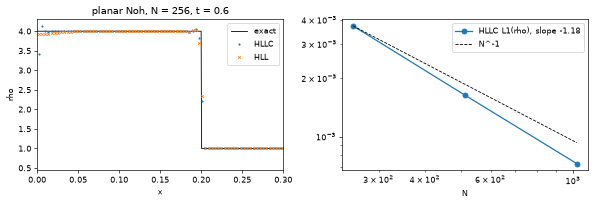

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5), dpi=60)
n = 256
x = (np.arange(2 * n) + 0.5) / n
xe = np.linspace(0, X_MAX, 600)
ax[0].plot(xe, np.where(xe < D * T, RHO_S, RHO0), "k-", lw=1, label="exact")
ax[0].plot(x, prof["hllc", n], ".", ms=3, label="HLLC")
ax[0].plot(x, prof["hll", n], "x", ms=3, label="HLL")
ax[0].set_xlim(0, X_MAX); ax[0].set_xlabel("x"); ax[0].set_ylabel("rho"); ax[0].legend()
ax[0].set_title("planar Noh, N = 256, t = 0.6")
ax[1].loglog(ns, [errs["hllc", n][0] for n in ns], "o-", label=f"HLLC L1(rho), slope -{order:.2f}")
ax[1].loglog(ns, errs["hllc", ns[0]][0] * ns[0] / np.array(ns), "k--", lw=1, label="N^-1")
ax[1].set_xlabel("N"); ax[1].legend()
fig.tight_layout()

The dip at the wall is the wall-heating error that every shock-capturing scheme shows on this
problem (an entropy excess left by the start-up of the reflected shock); it stays a fixed number of
cells wide and is left out of the L1.

## Cylindrical (2D)

The quarter plane [0, 1.7]² with the axes as reflecting symmetry planes; the inflow is warmed from
r = 1 and brought to rest from r = 1.5 (the test's ramp, which keeps the pressure positive).

In [5]:
L2D, A, AV, C_WARM = 1.7, 1.0, 1.5, 0.5


def noh2d(n):
    """rho at T and the cell radii, n² cells of [0, L2D]²."""
    x = (np.arange(n) + 0.5) * L2D / n
    X, Y = np.meshgrid(x, x, indexing="ij")
    r = np.hypot(X, Y)
    vr = U_IN * smoothstep((L2D - r) / (L2D - AV))
    p = P0 + RHO0 * (C_WARM * smoothstep((r - A) / (AV - A))) ** 2 / G
    U = np.zeros((4, n, n))                       # rho, rho vx, rho vy, E
    U[0] = RHO0
    U[1], U[2] = RHO0 * vr * X / r, RHO0 * vr * Y / r
    U[3] = p / (G - 1) + 0.5 * RHO0 * vr * vr
    cfg = replace(BASE, test_problem="Noh-2D", SPATIAL_DIMENSION=2, Nx=n, Ny=n,
                  Lx=L2D, Ly=L2D, BOUNDARY=2, gamma=G, t_end=T, write_snapshots=False,
                  output_dir="snapshots/nb05/run")
    res, wall = run(cfg, U0=U)
    return np.asarray(res.extra["U"], np.float64)[0], r, wall


def exact2d_point(r, t=T):
    return np.where(r < D * t, RHO0 * ((G + 1) / (G - 1)) ** 2, RHO0 * (1 + abs(U_IN) * t / np.maximum(r, 1e-300)))


def exact2d(n, sub=4):
    """Exact cell averages of rho (cells the shock cuts sampled sub² times)."""
    h = L2D / n
    x = (np.arange(n) + 0.5) * h
    X, Y = np.meshgrid(x, x, indexing="ij")
    r = np.hypot(X, Y)
    out = exact2d_point(r)
    cut = np.abs(r - D * T) < 0.5 * h * np.sqrt(2) + 1e-12
    o = (np.arange(sub) + 0.5) / sub - 0.5
    OX, OY = np.meshgrid(o, o, indexing="ij")
    rs = np.hypot(X[cut][:, None] + h * OX.ravel(), Y[cut][:, None] + h * OY.ravel())
    out[cut] = exact2d_point(rs).mean(axis=1)
    return out


# measured by the test (CPU, FP64, HLLC-minmod): L1(rho) = 3.8774e-02 at 128², 2.3315e-02 at 256²
res2 = {}
for n in (128, 256):
    rho, r, wall = noh2d(n)
    ball = r < X_MAX
    l1 = float(np.abs(rho - exact2d(n))[ball].sum() * (L2D / n) ** 2)
    res2[n] = (rho, r)
    print(f"2D N={n}: L1(rho) over r < {X_MAX} = {l1:.4e}   ({wall:.1f} s)")

2D N=128: L1(rho) over r < 0.3 = 3.8774e-02   (3.2 s)


2D N=256: L1(rho) over r < 0.3 = 2.3315e-02   (5.7 s)


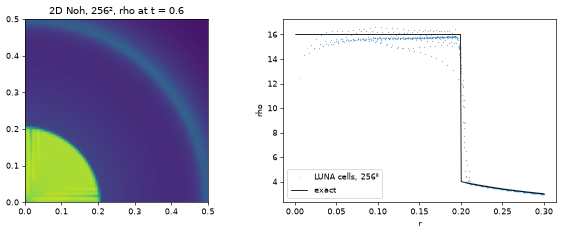

In [6]:
rho, r = res2[256]
rr = np.linspace(1e-3, X_MAX, 400)
fig, ax = plt.subplots(1, 2, figsize=(10, 4), dpi=60)
ax[0].imshow(rho.T, origin="lower", extent=(0, L2D, 0, L2D), cmap="viridis", vmax=18)
ax[0].set_xlim(0, 0.5); ax[0].set_ylim(0, 0.5); ax[0].set_title("2D Noh, 256², rho at t = 0.6")
ax[1].plot(r[r < X_MAX], rho[r < X_MAX], ".", ms=1, alpha=0.3, label="LUNA cells, 256²")
ax[1].plot(rr, exact2d_point(rr), "k-", lw=1, label="exact")
ax[1].set_xlabel("r"); ax[1].set_ylabel("rho"); ax[1].legend()
fig.tight_layout()

**What this shows.** Planar: L1 of rho, u, p are the test's measured values; the convergence is first order (1.18 over 256-1024; the test 1.04 over 256-2048), as for any shock, and the wall-heating dip is visible in the first cells. Cylindrical: L1(rho) = 3.88e-2 at 128² and 2.33e-2 at 256², the test's values.

Status (docs/CLAIMS.md): *validated*, `tests/test_hydro_hard_noh_planar.py:141`,
`tests/test_hydro_hard_noh_multid.py:286`. Known: HLLC carbuncles at grid-aligned strong shocks in
the full-box 2D Noh (strict xfail `tests/test_hydro_hard_noh_multid.py:309`); HLL stays planar.